# 08 · E7: speed on the laptop GPU, the pipeline and the app (RQ2)

**Question (RQ2, second half).** Can the detector run in real time on a laptop GPU, and what does the accuracy gained
by Faster R-CNN cost in speed?

This notebook runs **on the laptop** (NVIDIA GeForce RTX 3050 Laptop GPU), not on Kaggle: the point is the speed on
the hardware a driver-assistance prototype would use. It then builds the deployed pipeline (`app/pipeline.py`),
checks that the pipeline reproduces the test score of notebook 05, and builds the demo app (`app/app.py`).

Only the **test split** is needed locally (`data/images_test.zip`, `data/labels_yolo.zip` and `data/tables/`,
downloaded from the data-preparation step).

**Run it with the laptop plugged in**: on battery the GPU is throttled and every number drops.

**Setup.** Runs on the laptop, from the `notebooks/` folder. Imports the shared code (`kitti_common.py`, written and
explained in `00_common.ipynb`). Results and weights are read from the project's `results/` and `weights/` folders,
which hold the outputs of the Kaggle notebooks 01-07.

In [1]:
import os, sys, json, time, platform, importlib
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))          # kitti_common.py sits next to this notebook (written by 00_common)
from kitti_common import *
from kitti_common import _save    # figure helper (underscore names are not exported by *)
import cv2
seed_everything()
print("local" if not ON_KAGGLE else "Kaggle", "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none",
      "| project root:", OUT)

C:\Users\Fizza\anaconda3\envs\torch-gpu\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


local | GPU: NVIDIA GeForce RTX 3050 Laptop GPU | project root: C:\Users\Fizza\Downloads\DSTT\Project\part2-v2


## 1. The test split on this laptop

In [2]:
tables = prepare_data(["test"])
images, ann, ign = tables
test_ids = split_ids(images, "test")
recs = {e: load_record(e) for e in ["E0", "E2", "E3", "FINAL", "E6"]}
pd.DataFrame({e: {"image size": r["imgsz"], "test primary": round(r["test_primary_mAP50_mod"], 3)}
              for e, r in recs.items()}).T

data ready in C:\Users\Fizza\Downloads\DSTT\Project\part2-v2\data: test 1543


,image size,test primary
E0,640.0,0.542
E2,640.0,0.716
E3,800/1333,0.854
FINAL,960.0,0.799
E6,960.0,0.804


## 2. E7: speed benchmark

**Protocol.**

* **Batch size 1**: one camera frame at a time, as in a car.
* 200 test images are **loaded into memory first**, so disk reading is not timed.
* The timed call is the **whole model call**: pre-processing (resize, normalise), the network and non-maximum
  suppression, ending with a GPU synchronise.
* The GPU is first kept busy for 15 s so it reaches its boost clock. Every model is then measured in **2 interleaved
  rounds**, and the faster round is kept, so the order of the models does not bias the result.
* 50 warm-up frames, then 300 timed frames (100 for Faster R-CNN, which is much slower). **FPS = 1000 / median
  latency**; the median is robust to the clock and heat spikes of a laptop GPU. The mean and the 95th percentile are
  reported too.
* **FP32** (full precision) and **FP16** (half precision) are both measured.

E0 has exactly the same network and image size as E2, so it has the same speed and is not measured separately. E5
has the same network and image size as FINAL.

**Real time** here means **at least 30 FPS** (a typical camera frame rate; KITTI's own camera records at 10 FPS, so
30 FPS leaves room for the rest of a driver-assistance system).

In [3]:
REALTIME_FPS = 30
BENCH = ["E2", "E3", "FINAL", "E6"]
bench_ids = test_ids[:: max(1, len(test_ids) // 200)][:200]
frames = [cv2.imread(str(p)) for p in image_paths(bench_ids, "test")]


def _timeit(fn, frames, n, warmup=50):
    for i in range(warmup):
        fn(frames[i % len(frames)])
    torch.cuda.synchronize()
    lat, parts = [], []
    for i in range(n):
        t = time.perf_counter()
        out = fn(frames[i % len(frames)])
        torch.cuda.synchronize()
        lat.append((time.perf_counter() - t) * 1000)
        if isinstance(out, dict):
            parts.append(out)
    lat = np.array(lat)
    res = {"ms_p50": np.median(lat), "ms_mean": lat.mean(), "ms_p95": np.percentile(lat, 95), "fps": 1000 / np.median(lat)}
    if parts:     # Ultralytics' own split of the time: pre-processing, network ("inference"), NMS ("postprocess")
        res.update({f"ms_{k}": float(np.median([p[k] for p in parts])) for k in parts[0]})
    return res


def bench_yolo(weights, imgsz, half, n):
    from ultralytics import YOLO
    m = YOLO(str(weights))
    q = "fp16" if half else None
    return _timeit(lambda f: m.predict(f, imgsz=imgsz, quantize=q, conf=0.25, verbose=False)[0].speed, frames, n)


def bench_frcnn(weights, half, n):
    m = load_frcnn(weights, "cuda")
    m.roi_heads.score_thresh = 0.25

    @torch.no_grad()
    def f(img):
        x = torch.from_numpy(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)).cuda().permute(2, 0, 1).float() / 255
        with torch.autocast("cuda", dtype=torch.float16, enabled=half):
            m([x])
    return _timeit(f, frames, n)


assert torch.cuda.is_available(), "the speed benchmark needs the GPU"
x = torch.randn(4096, 4096, device="cuda")              # bring the laptop GPU to its boost clock
t_end = time.time() + 15
while time.time() < t_end:
    x = (x @ x).clamp_(-1, 1)
torch.cuda.synchronize(); del x

best = {}
for rnd, e in tqdm([(r, e) for r in range(2) for e in BENCH], desc="E7 speed benchmark"):
    for half in (False, True):
        if e == "E3":
            r, imgsz = bench_frcnn(WEIGHTS / "E3.pt", half, 100), "800/1333"
        else:
            imgsz = int(recs[e]["imgsz"])
            r = bench_yolo(WEIGHTS / f"{e}.pt", imgsz, half, 300)
        row = {"model": e, "precision": "FP16" if half else "FP32", "imgsz": imgsz, **{k: round(float(v), 2) for k, v in r.items()}}
        key = (e, row["precision"])
        if key not in best or row["fps"] > best[key]["fps"]:
            best[key] = row
        torch.cuda.empty_cache()

speed = pd.DataFrame(list(best.values()))
speed["test_primary"] = speed.model.map(lambda e: round(recs[e]["test_primary_mAP50_mod"], 3))
speed["real_time"] = speed.fps >= REALTIME_FPS
speed.to_csv(exp_dir("E7") / "speed.csv", index=False)
print(torch.cuda.get_device_name(0), "| torch", torch.__version__, "|", platform.system())
speed

E7 speed benchmark:   0%|          | 0/8 [00:00<?, ?it/s]

E7 speed benchmark:  12%|█▎        | 1/8 [00:24<02:54, 24.96s/it]

E7 speed benchmark:  25%|██▌       | 2/8 [00:52<02:37, 26.31s/it]

E7 speed benchmark:  38%|███▊      | 3/8 [01:05<01:42, 20.58s/it]

E7 speed benchmark:  50%|█████     | 4/8 [01:21<01:14, 18.62s/it]

E7 speed benchmark:  62%|██████▎   | 5/8 [01:37<00:52, 17.48s/it]

... (2 outputs left out)

E7 speed benchmark: 100%|██████████| 8/8 [02:35<00:00, 17.97s/it]

E7 speed benchmark: 100%|██████████| 8/8 [02:35<00:00, 19.42s/it]

NVIDIA GeForce RTX 3050 Laptop GPU | torch 2.14.1+cu130 | Windows


,model,precision,imgsz,ms_p50,ms_mean,ms_p95,fps,ms_preprocess,ms_inference,ms_postprocess,test_primary,real_time
0,E2,FP32,640,18.90,27.51,65.32,52.91,1.07,14.48,2.77,0.716,True
1,E2,FP16,640,18.25,23.60,48.86,54.79,0.99,14.07,2.59,0.716,True
2,E3,FP32,800/1333,91.79,92.40,97.10,10.89,NaN,NaN,NaN,0.854,False
3,E3,FP16,800/1333,71.67,73.71,82.69,13.95,NaN,NaN,NaN,0.854,False
4,FINAL,FP32,960,21.77,21.54,28.15,45.94,1.92,16.14,3.06,0.799,True
5,FINAL,FP16,960,16.73,17.05,20.37,59.79,1.42,12.33,2.38,0.799,True
6,E6,FP32,960,21.00,21.34,29.59,47.63,1.78,15.36,2.86,0.804,True
7,E6,FP16,960,22.26,22.44,29.49,44.92,1.81,16.54,2.84,0.804,True


**Speed against accuracy.** Each model is one point: test accuracy (primary metric) against frames per second.
Filled markers are FP16, hollow markers FP32. The dashed line is the real-time threshold.

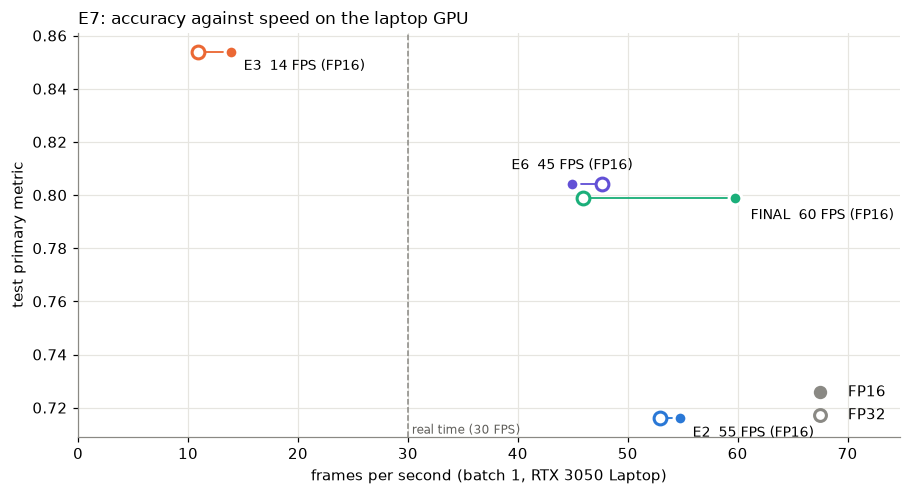

In [4]:
fig, ax = plt.subplots(figsize=(8.5, 4.6))
for e in BENCH:
    s = speed[speed.model == e].set_index("precision")
    acc = s.test_primary.iloc[0]
    ax.plot([s.fps["FP32"], s.fps["FP16"]], [acc, acc], color=MODEL_C[e], lw=1.2, zorder=2)
    ax.scatter(s.fps["FP32"], acc, s=70, facecolor="white", edgecolor=MODEL_C[e], lw=2, zorder=3)
    ax.scatter(s.fps["FP16"], acc, s=70, color=MODEL_C[e], edgecolor="white", lw=2, zorder=3)
    off, ha = {"E6": ((0, 10), "center"), "FINAL": ((10, -14), "left")}.get(e, ((8, -12), "left"))
    ax.annotate(f"{e}  {s.fps['FP16']:.0f} FPS (FP16)", (s.fps["FP16"], acc), textcoords="offset points", xytext=off,
                ha=ha, fontsize=9)
ax.axvline(REALTIME_FPS, color="#8a8984", ls="--", lw=1)
ax.text(REALTIME_FPS, ax.get_ylim()[0], f" real time ({REALTIME_FPS} FPS)", color="#5f5e5a", fontsize=8, va="bottom")
ax.scatter([], [], s=60, color="#8a8984", label="FP16")
ax.scatter([], [], s=60, facecolor="white", edgecolor="#8a8984", lw=2, label="FP32")
ax.set_xlabel("frames per second (batch 1, RTX 3050 Laptop)"); ax.set_ylabel("test primary metric")
ax.set_xlim(0, speed.fps.max() * 1.25); ax.legend(loc="lower right")
ax.set_title("E7: accuracy against speed on the laptop GPU", loc="left")
_save(fig, "E7", "speed_accuracy")

In [5]:
rec7 = save_record("E7", "inference speed on the laptop GPU, batch 1, FP32 and FP16", "RQ2",
                   gpu=torch.cuda.get_device_name(0), torch_version=torch.__version__, realtime_fps=REALTIME_FPS,
                   **{f"fps_{r.model}_{r.precision}": r.fps for r in speed.itertuples()},
                   **{f"ms_p50_{r.model}_{r.precision}": r.ms_p50 for r in speed.itertuples()})

## 3. The deployed pipeline (`app/pipeline.py`)

One camera image in, obstacles, a distance estimate and a driver warning out. The detector is the **FINAL** model,
as decided in notebook 05 (settings chosen on validation). The warning is a simple, explainable rule on top of the
detector, not a learned model:

* **Distance**: pinhole-camera estimate `Z = f · H / h`, with `h` the box height in pixels, `H` a typical real height
  of the class (KITTI averages) and `f` the focal length (721.5 px for KITTI, scaled with the image width). It is
  rough: it assumes a KITTI-like camera and is wrong for truncated or partly visible objects.
* **Driving corridor**: a trapezoid covering roughly our own lane, narrow at the horizon and wider at the bottom.
* **DANGER**: an obstacle in the corridor closer than 10 m, or a pedestrian / cyclist in the corridor closer than
  15 m. **CAUTION**: an obstacle in the corridor closer than 25 m, or a pedestrian / cyclist anywhere closer than
  10 m. **CLEAR** otherwise.

In [6]:
(OUT / "app" / "examples").mkdir(parents=True, exist_ok=True)

In [7]:
%%writefile ../app/pipeline.py
"""Deployed pipeline: one camera image in -> obstacles, distance estimate and a driver warning out.
Written by notebooks/08_speed_and_app.ipynb (section 3); edit it there.

    from pipeline import ObstacleDetector       # app/ on the path
    det = ObstacleDetector()                    # weights/FINAL.pt, at the image size it was trained with
    out = det.predict("street.png")             # dict: detections (DataFrame), level, message, image, ms
"""
import json
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd

ROOT = Path(__file__).resolve().parents[1]           # project root (this file lives in app/)
RESULTS_DIR, WEIGHTS_DIR = ROOT / "results", ROOT / "weights"
KITTI_FOCAL_PX = 721.5                                # KITTI camera focal length in pixels (P2 matrix)

REAL_HEIGHT_M = {"Car": 1.53, "Van": 2.21, "Truck": 3.25, "Pedestrian": 1.76, "Person_sitting": 1.27,
                 "Cyclist": 1.74, "Tram": 3.53, "Misc": 1.9}
VULNERABLE = {"Pedestrian", "Cyclist", "Person_sitting"}
COLORS = {"Car": (0, 200, 0), "Van": (0, 160, 255), "Truck": (0, 220, 255), "Pedestrian": (0, 0, 255),
          "Person_sitting": (180, 0, 255), "Cyclist": (255, 200, 0), "Tram": (255, 255, 255), "Misc": (200, 0, 200)}
LEVEL_COLOR = {"CLEAR": (0, 170, 0), "CAUTION": (0, 165, 255), "DANGER": (0, 0, 230)}
HORIZON, HALF_TOP, HALF_BOTTOM = 0.45, 0.03, 0.18     # ego-lane trapezoid (fractions of the image size)


def in_corridor(cx, y2, w, h):
    """Bottom centre of the box inside the ego-lane trapezoid."""
    t = np.clip((y2 / h - HORIZON) / (1 - HORIZON), 0, 1)
    half = HALF_TOP + t * (HALF_BOTTOM - HALF_TOP)
    return (y2 / h > HORIZON) & (np.abs(cx / w - 0.5) <= half)


def assess(dets, w, h):
    """Adds distance_m / in_corridor / risk columns; returns (dets, level, message)."""
    if len(dets) == 0:
        return dets.assign(distance_m=[], in_corridor=[], risk=[]), "CLEAR", "No obstacles detected."
    d = dets.copy()
    f = KITTI_FOCAL_PX * w / 1242.0
    d["distance_m"] = (f * d["type"].map(REAL_HEIGHT_M) / (d.y2 - d.y1).clip(lower=1)).round(1)
    d["in_corridor"] = in_corridor((d.x1 + d.x2) / 2, d.y2, w, h)
    vul = d["type"].isin(VULNERABLE)
    danger = d.in_corridor & ((d.distance_m < 10) | (vul & (d.distance_m < 15)))
    caution = (d.in_corridor & (d.distance_m < 25)) | (vul & (d.distance_m < 10))
    d["risk"] = np.where(danger, "DANGER", np.where(caution, "CAUTION", ""))
    if danger.any():
        r = d[danger].sort_values("distance_m").iloc[0]
        return d, "DANGER", f"DANGER: {r.type} ahead at about {r.distance_m:.0f} m"
    if caution.any():
        r = d[caution].sort_values("distance_m").iloc[0]
        return d, "CAUTION", f"CAUTION: {r.type} at about {r.distance_m:.0f} m"
    return d, "CLEAR", f"{len(d)} obstacle(s) detected, none in the driving path nearby."


def draw(img_bgr, dets, level, message, ms=None):
    out = img_bgr.copy()
    h, w = out.shape[:2]
    pts = np.array([[(0.5 - HALF_TOP) * w, HORIZON * h], [(0.5 + HALF_TOP) * w, HORIZON * h],
                    [(0.5 + HALF_BOTTOM) * w, h - 1], [(0.5 - HALF_BOTTOM) * w, h - 1]], np.int32)
    overlay = out.copy()
    cv2.fillPoly(overlay, [pts], (255, 255, 0))
    out = cv2.addWeighted(overlay, 0.15, out, 0.85, 0)
    cv2.polylines(out, [pts], True, (255, 255, 0), 1, cv2.LINE_AA)
    for r in dets.itertuples():
        c = COLORS.get(r.type, (255, 255, 255))
        cv2.rectangle(out, (int(r.x1), int(r.y1)), (int(r.x2), int(r.y2)), c, 3 if r.risk else 2)
        label = f"{r.type} {r.score:.2f} ~{r.distance_m:.0f}m"
        (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.45, 1)
        y = max(int(r.y1) - 4, th + 2)
        cv2.rectangle(out, (int(r.x1), y - th - 3), (int(r.x1) + tw + 2, y + 2), c, -1)
        cv2.putText(out, label, (int(r.x1) + 1, y), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 0), 1, cv2.LINE_AA)
    banner = message + (f"   |   {ms:.0f} ms ({1000 / ms:.0f} FPS)" if ms else "")
    cv2.rectangle(out, (0, 0), (w, 26), LEVEL_COLOR[level], -1)
    cv2.putText(out, banner, (8, 18), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 1, cv2.LINE_AA)
    return out


class ObstacleDetector:
    def __init__(self, weights=None, imgsz=None, conf=0.25, half=True, device=None):
        from ultralytics import YOLO
        import torch
        weights = Path(weights or WEIGHTS_DIR / "FINAL.pt")
        if imgsz is None:                              # the image size the model was trained with (its record)
            rec = RESULTS_DIR / weights.stem / "record.json"
            imgsz = int(json.loads(rec.read_text())["imgsz"]) if rec.exists() else 640
        self.model = YOLO(str(weights))
        self.name, self.imgsz, self.conf = weights.stem, imgsz, conf
        self.device = device if device is not None else (0 if torch.cuda.is_available() else "cpu")
        self.half = half and self.device != "cpu"
        self.names = self.model.names
        self.detect(np.zeros((375, 1242, 3), np.uint8))     # warm-up: the first GPU call is slow

    def detect(self, img_bgr, conf=None):
        r = self.model.predict(img_bgr, imgsz=self.imgsz, conf=conf or self.conf,
                               quantize="fp16" if self.half else None, device=self.device, verbose=False)[0]
        b = r.boxes
        xyxy = b.xyxy.cpu().numpy() if len(b) else np.zeros((0, 4))
        return pd.DataFrame({"type": [self.names[int(c)] for c in b.cls.cpu().numpy()] if len(b) else [],
                             "score": b.conf.cpu().numpy() if len(b) else [],
                             "x1": xyxy[:, 0], "y1": xyxy[:, 1], "x2": xyxy[:, 2], "y2": xyxy[:, 3]})

    def predict(self, image, conf=None):
        """image: a path, a BGR numpy array (OpenCV) or a PIL image."""
        if isinstance(image, (str, Path)):
            img = cv2.imread(str(image))
        elif hasattr(image, "convert"):
            img = cv2.cvtColor(np.array(image.convert("RGB")), cv2.COLOR_RGB2BGR)
        else:
            img = image
        t = time.perf_counter()
        dets = self.detect(img, conf)
        ms = (time.perf_counter() - t) * 1000
        h, w = img.shape[:2]
        dets, level, msg = assess(dets, w, h)
        return {"detections": dets.round(3), "level": level, "message": msg, "ms": ms,
                "image": draw(img, dets, level, msg, ms)}


_DEFAULT = None


def predict(image_path, **kw):
    """Convenience wrapper: predict(image_path) -> result dict (loads FINAL once)."""
    global _DEFAULT
    if _DEFAULT is None:
        _DEFAULT = ObstacleDetector(**kw)
    return _DEFAULT.predict(image_path)

Overwriting ../app/pipeline.py


**Check: does the deployed pipeline reproduce the reported test score?** The pipeline's detector is run on all test
images at a very low threshold (as the evaluator needs) and scored with the same KITTI evaluator. The result should
match notebook 05 closely. It cannot be identical: this is a different GPU, and the pipeline uses Ultralytics' default
non-maximum suppression (IoU 0.7, up to 300 boxes) instead of the evaluation setting (IoU 0.6, 100 boxes).

In [8]:
sys.path.insert(0, str(OUT / "app"))
import pipeline
importlib.reload(pipeline)
det = pipeline.ObstacleDetector()          # FINAL, FP16
print("pipeline model:", det.name, "| image size:", det.imgsz)

rows = []
for iid, p in tqdm(list(zip(test_ids, image_paths(test_ids, "test"))), desc="pipeline on the test set"):
    d = det.detect(cv2.imread(str(p)), conf=0.001)
    rows.append(d.assign(image_id=iid))
pipe_preds = pd.concat(rows, ignore_index=True)[COLUMNS]
pipe_summ, _ = Evaluator(ann, ign, test_ids).summary(pipe_preds)
reported = {k[5:]: v for k, v in recs["FINAL"].items() if k.startswith("test_") and isinstance(v, (int, float))}
cmp = headline(**{"notebook 05 (Kaggle T4)": reported, "deployed pipeline (laptop)": pipe_summ})
cmp["difference"] = (cmp.iloc[:, 1] - cmp.iloc[:, 0]).round(3)
cmp

pipeline model: FINAL | image size: 960


pipeline on the test set:   0%|          | 0/1543 [00:00<?, ?it/s]

pipeline on the test set:   0%|          | 3/1543 [00:00<01:00, 25.41it/s]

pipeline on the test set:   0%|          | 6/1543 [00:00<00:58, 26.44it/s]

pipeline on the test set:   1%|          | 9/1543 [00:00<01:06, 23.00it/s]

pipeline on the test set:   1%|          | 12/1543 [00:00<01:09, 22.10it/s]

... (445 outputs left out)

pipeline on the test set: 100%|█████████▉| 1540/1543 [00:56<00:00, 28.93it/s]

pipeline on the test set: 100%|██████████| 1543/1543 [00:56<00:00, 27.01it/s]

pipeline on the test set: 100%|██████████| 1543/1543 [00:56<00:00, 27.13it/s]

,notebook 05 (Kaggle T4),deployed pipeline (laptop),difference
"Primary (Car/Ped/Cyc, Moderate)",0.799,0.799,0.000
Car,0.967,0.967,0.000
Pedestrian,0.797,0.799,0.002
Cyclist,0.631,0.631,0.000
Easy (3 classes),0.830,0.831,0.001
Hard (3 classes),0.780,0.781,0.001
Car AP@0.7,0.935,0.935,0.000
"mAP@0.5, all 8 classes",0.526,0.526,0.000
"mAP@0.5:0.95, all 8 classes",0.333,0.332,-0.001


## 4. Demo

The pipeline on test images, one for each warning level (the first test image that produces it), and on one image
with simulated low light, comparing FINAL with the weather-augmented E6.

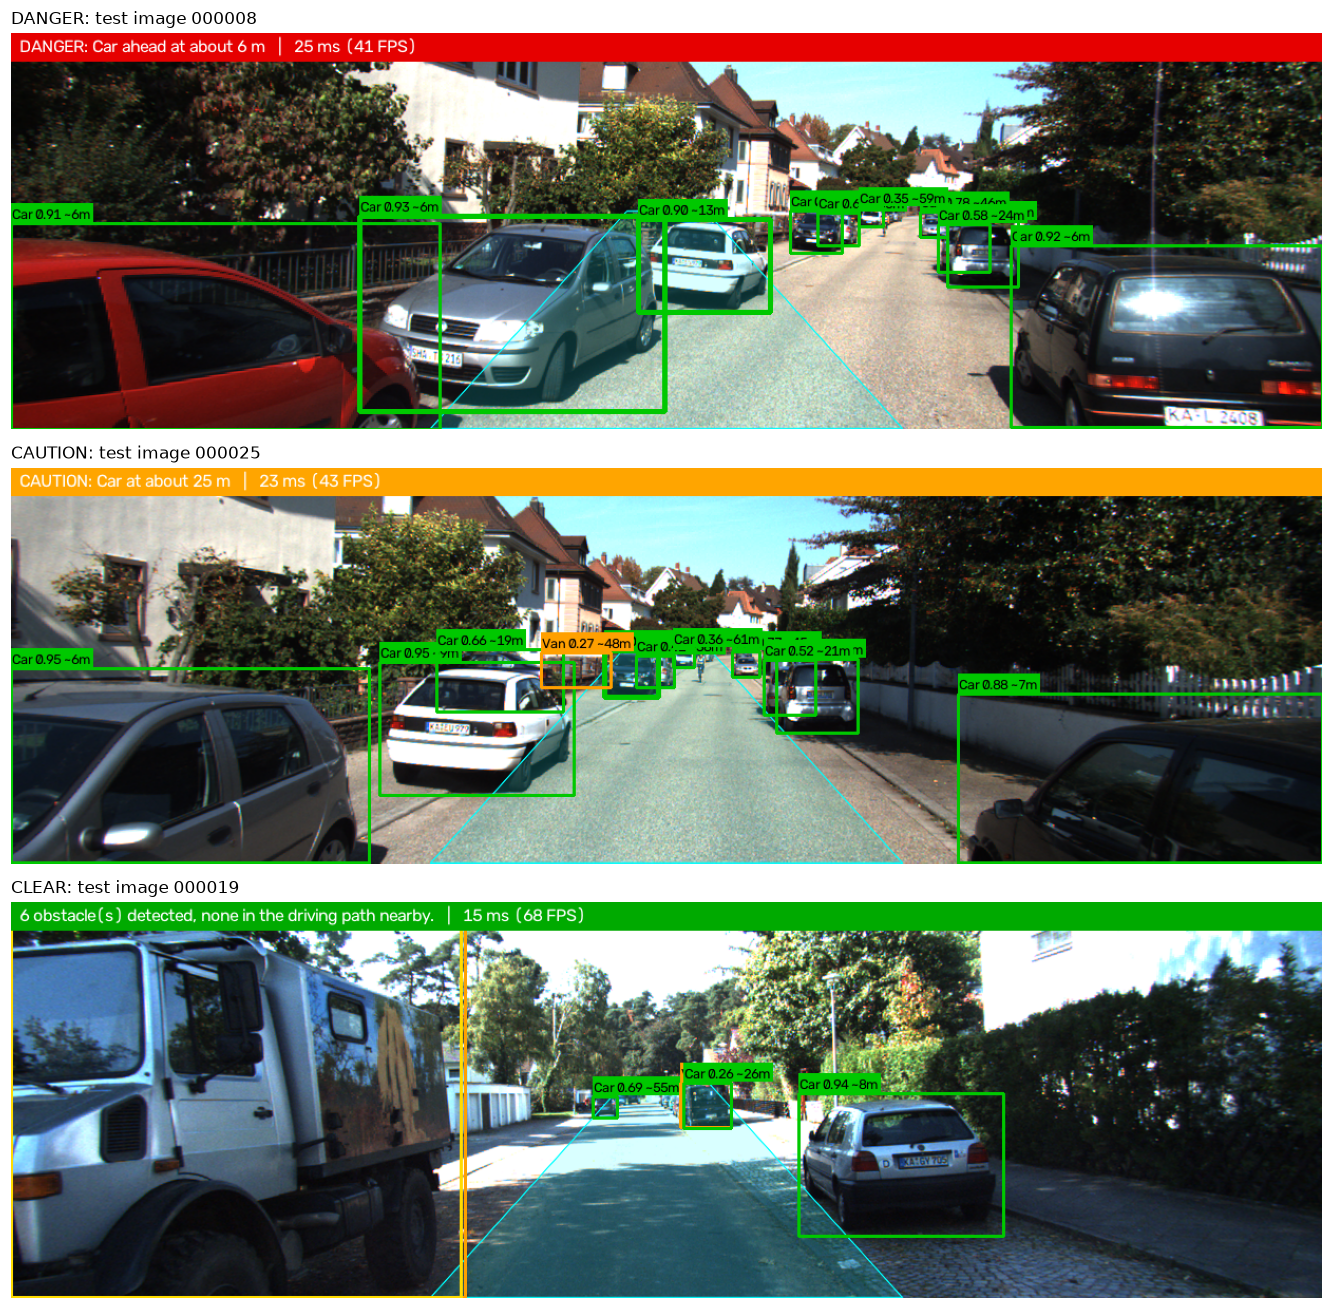

detections behind the DANGER warning (nearest first):


,type,score,distance_m,in_corridor,risk
2,Car,0.909,5.7,False,
0,Car,0.934,6.0,True,DANGER
1,Car,0.924,6.4,False,
3,Car,0.903,12.6,True,CAUTION
4,Car,0.893,17.8,False,
8,Car,0.583,24.4,False,
5,Car,0.890,27.5,False,
7,Car,0.644,35.6,False,
6,Car,0.784,45.5,False,
9,Car,0.350,58.9,False,


In [9]:
for f in frames[:60]:                      # the GPU idled during the CPU-only scoring above: bring it back to speed
    det.detect(f)
found = {}
for iid, p in zip(test_ids, image_paths(test_ids, "test")):
    out = det.predict(p)
    if out["level"] not in found:
        found[out["level"]] = (iid, out)
    if len(found) == 3:
        break
fig, ax = plt.subplots(len(found), 1, figsize=(13, 4.0 * len(found)))
for a, lvl in zip(np.atleast_1d(ax), ["DANGER", "CAUTION", "CLEAR"]):
    if lvl in found:
        iid, out = found[lvl]
        a.imshow(out["image"][..., ::-1]); a.set_title(f"{lvl}: test image {iid}", loc="left")
    a.axis("off")
_save(fig, "E7", "demo_levels")
lvl = "DANGER" if "DANGER" in found else next(iter(found))
print(f"detections behind the {lvl} warning (nearest first):")
found[lvl][1]["detections"][["type", "score", "distance_m", "in_corridor", "risk"]].sort_values("distance_m")

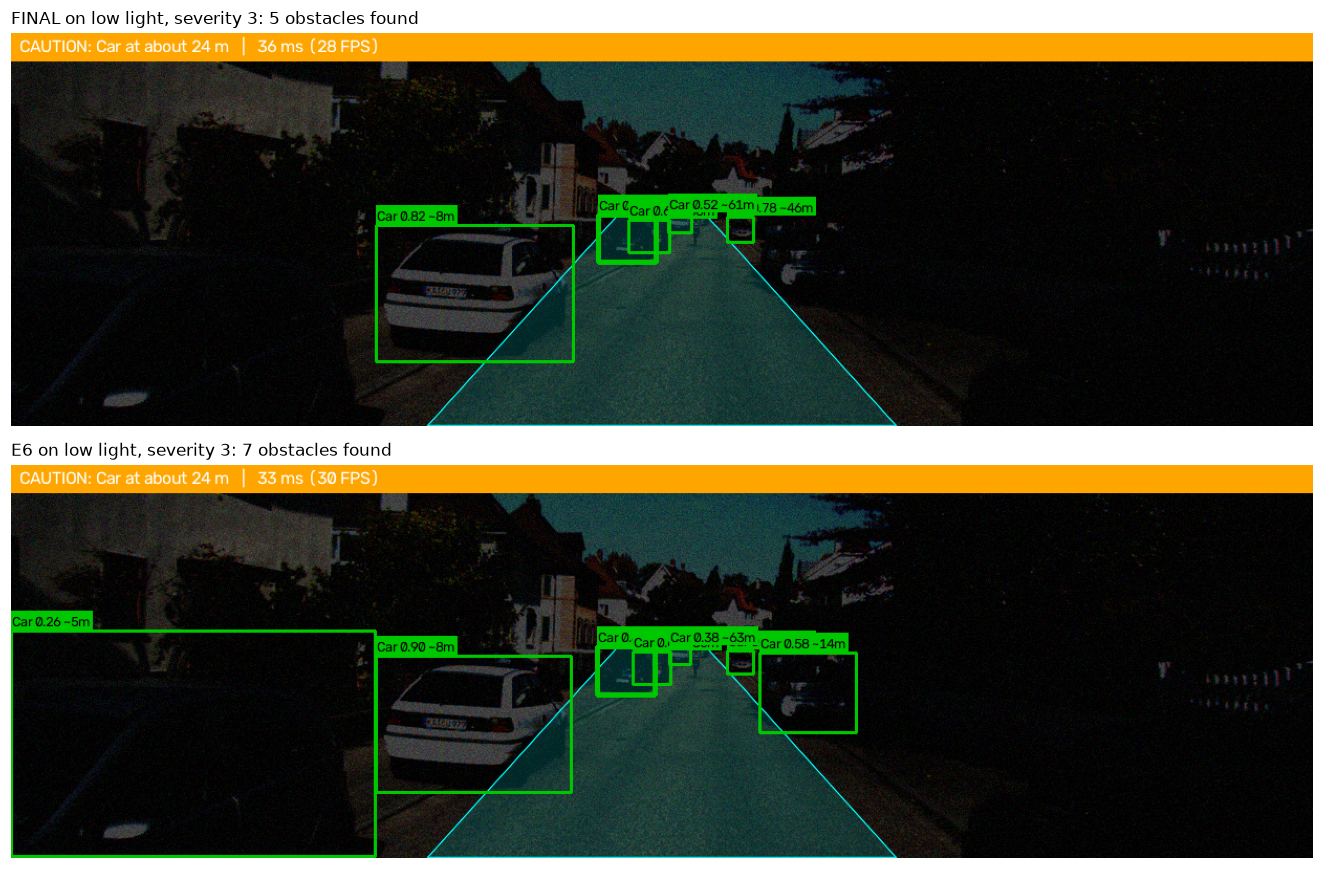

In [10]:
det_e6 = pipeline.ObstacleDetector(WEIGHTS / "E6.pt")
iid = found.get("CAUTION", next(iter(found.values())))[0]
dark = corrupt(cv2.imread(str(DATA / "images" / "test" / f"{iid}.png")), "low_light", 3, iid)
fig, ax = plt.subplots(2, 1, figsize=(13, 8))
for a, d in zip(ax, [det, det_e6]):
    out = d.predict(dark)
    a.imshow(out["image"][..., ::-1]); a.axis("off")
    a.set_title(f"{d.name} on low light, severity 3: {len(out['detections'])} obstacles found", loc="left")
_save(fig, "E7", "demo_low_light")

Example images for the app (the clean ones above plus two simulated-weather versions):

In [11]:
ex = OUT / "app" / "examples"
for lvl, (iid, _) in found.items():
    shutil.copy(DATA / "images" / "test" / f"{iid}.png", ex / f"{iid}.png")
for kind in ["fog", "low_light"]:
    cv2.imwrite(str(ex / f"{iid}_{kind}2.png"), corrupt(cv2.imread(str(DATA / "images" / "test" / f"{iid}.png")), kind, 2, iid))
sorted(p.name for p in ex.glob("*.png"))

['000008.png',
 '000019.png',
 '000025.png',
 '000025_fog2.png',
 '000025_low_light2.png']

## 5. The app (`app/app.py`)

A small Gradio web app around the pipeline: upload a road image, get the detections, the distance estimates, the
warning level and the time per image. It runs fully offline once the weights are present:

```
python app/app.py        # then open http://127.0.0.1:7860
```

The model can be switched between **FINAL** (default) and the weather-augmented **E6**. The first one or two images after
start-up are slower, while the laptop GPU raises its clock.

In [12]:
%%writefile ../app/app.py
"""Gradio demo: upload a road image -> detected obstacles, distance estimate, warning level and speed.
Written by notebooks/08_speed_and_app.ipynb (section 5).

    python app/app.py            # opens http://127.0.0.1:7860
"""
import sys
from pathlib import Path

import cv2
import gradio as gr

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT / "app"))
from pipeline import ObstacleDetector, WEIGHTS_DIR  # noqa: E402

MODELS = {"FINAL (default)": "FINAL", "E6 (weather-augmented)": "E6"}
_DETECTORS = {}
EXAMPLES = sorted(str(p) for p in (ROOT / "app" / "examples").glob("*.png"))


def detector(name):
    if name not in _DETECTORS:
        _DETECTORS[name] = ObstacleDetector(WEIGHTS_DIR / f"{name}.pt")
    return _DETECTORS[name]


def run(image, conf, model="FINAL (default)"):
    if image is None:
        return None, "Upload an image first.", None
    out = detector(MODELS.get(model, model)).predict(image, conf=conf)
    rgb = cv2.cvtColor(out["image"], cv2.COLOR_BGR2RGB)
    table = out["detections"][["type", "score", "distance_m", "in_corridor", "risk"]] \
        .sort_values("distance_m").rename(columns={"type": "class", "distance_m": "distance (m, approx.)"})
    status = f"### {out['level']}\n{out['message']}\n\nInference: {out['ms']:.0f} ms ({1000 / out['ms']:.0f} FPS)"
    return rgb, status, table


with gr.Blocks(title="KITTI obstacle detection") as demo:
    gr.Markdown("# Camera-based obstacle detection\nYOLOv8s fine-tuned on KITTI (Group 16). Upload a front-camera "
                "road image. Distances are rough pinhole estimates that assume a KITTI-like camera.")
    with gr.Row():
        with gr.Column(scale=1):
            inp = gr.Image(type="pil", label="Road image", sources=["upload"])
            model = gr.Radio(list(MODELS), value="FINAL (default)", label="Model")
            conf = gr.Slider(0.05, 0.9, value=0.25, step=0.05, label="Confidence threshold")
            btn = gr.Button("Detect", variant="primary")
        with gr.Column(scale=2):
            out_img = gr.Image(label="Detections")
            status = gr.Markdown()
    table = gr.Dataframe(label="Obstacles (nearest first)")
    if EXAMPLES:
        gr.Examples(EXAMPLES, inputs=inp)
    btn.click(run, [inp, conf, model], [out_img, status, table])
    inp.change(run, [inp, conf, model], [out_img, status, table])

if __name__ == "__main__":
    demo.launch()

Overwriting ../app/app.py


**Check:** the app module loads and answers one example image (without starting the web server).

In [13]:
import importlib.util
from PIL import Image
spec = importlib.util.spec_from_file_location("kitti_app", OUT / "app" / "app.py")
app = importlib.util.module_from_spec(spec); spec.loader.exec_module(app)
img, status, table = app.run(Image.open(app.EXAMPLES[0]), 0.25, "FINAL (default)")
print(Path(app.EXAMPLES[0]).name, "->", status.replace("\n", " "))
table

000008.png -> ### DANGER DANGER: Car ahead at about 6 m  Inference: 66 ms (15 FPS)


,class,score,"distance (m, approx.)",in_corridor,risk
2,Car,0.909,5.7,False,
0,Car,0.934,6.0,True,DANGER
1,Car,0.924,6.4,False,
3,Car,0.903,12.6,True,CAUTION
4,Car,0.893,17.8,False,
8,Car,0.583,24.4,False,
5,Car,0.890,27.5,False,
7,Car,0.644,35.6,False,
6,Car,0.784,45.5,False,
9,Car,0.350,58.9,False,


## Observations

- **Every YOLOv8s model runs in real time on the laptop GPU:** 45–60 FPS at batch 1 (about 17–22 ms per image,
  including pre-processing and non-maximum suppression), well above the 30 FPS threshold.
- **Faster R-CNN does not: 11–14 FPS** (72–92 ms per image), about **4 times slower** than FINAL, while it is the most
  accurate model (test 0.854 against 0.799).
- **The differences between the YOLO models are measurement noise.** FINAL and E6 are the same network at the same
  image size, yet they measured 60 and 45 FPS in FP16; a repeat of the whole benchmark moved single numbers by up to
  about 14 FPS. At batch 1 the laptop GPU spends much of each call on fixed overheads (launching work, copying the image,
  clock changes), so **FP16 and the larger 960 px input barely change the speed**. The solid conclusion is the gap
  between the two families (YOLO about 4× faster), not the ranking within YOLO.
- **The deployed pipeline reproduces the reported result:** `app/pipeline.py` scores **0.799** on the test set, exactly
  notebook 05's number (individual metrics within 0.002), on a different GPU and with default NMS settings.
- **The warning rule behaves sensibly on the examples:** a car 6 m ahead in our lane gives DANGER, a car at ~25 m in the
  corridor CAUTION, and parked cars beside the road do not raise a warning. The distances are rough pinhole estimates
  and are unreliable for objects cut off at the image border.
- **The weather-augmented E6 helps in the dark:** on the severity-3 low-light image it finds 7 obstacles against 5 for
  FINAL, including the dark parked car on the left. This matches notebook 07, where E6's biggest gain was low light.
- **Decision for the app:** FINAL stays the default (chosen on validation; real time; 0.799 test). E6 is offered as a
  switch in the app, because it costs nothing on clean images and is clearly more robust in bad conditions.